# 02. Visium HD CRC — Cell-Type Cartography, Cosine Graph & Spatial Deconvolution

This notebook investigates cellular heterogeneity in the **10x Genomics Visium HD Human Colorectal Cancer (CRC)** dataset.

---

### Analytical Workflow
1. **Analytic Pearson Residuals Normalization:** Models count variation directly using a negative binomial null model (`scanpy.experimental.pp.normalize_pearson_residuals`), preserving raw integer counts in `adata.layers["counts"]`.
2. **Cosine Manifold & Custom UMAP:** Builds a k-nearest neighbor (kNN) graph under the **cosine metric** and computes a high-resolution UMAP with **`min_dist = 0.02`** and **`spread = 2.0`** to separate discrete lineages while revealing microenvironment transitions.
3. **Multi-Lineage Marker Profiling:** Characterizes Epithelial/Malignant (*EPCAM*, *CDX2*, *LGR5*), Stromal/CAFs (*ACTA2*, *COL1A1*), Endothelial (*PECAM1*), Lymphoid (*CD3D*, *CD8A*, *MS4A1*), and Myeloid (*CD68*, *SPP1*) populations via dot plots and spatial overlays.
4. **Automated CellTypist Annotation:** Applies the pre-trained `Human_Colorectal_Cancer.pkl` model to predict cell identities and compute assignment confidence across spots.
5. **Continuous Spatial Deconvolution & Niche Co-occurrence:** Extracts spot-level cell-type mixture probabilities to map spatial abundance gradients and compute cell-cell spatial correlation matrices.


In [1]:
from pathlib import Path
import time
import h5py
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import anndata as ad
import scanpy as sc
import squidpy as sq
import celltypist
from celltypist import models

# Configure plotting aesthetics
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
sns.set_theme(style='whitegrid', font_scale=1.05)

print("Environment successfully initialized.")
print(f"Scanpy: {sc.__version__} | AnnData: {ad.__version__} | CellTypist: {celltypist.__version__}")


D:\Projects\spatial-microenvironment-profiler\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Environment successfully initialized.
Scanpy: 1.12.5 | AnnData: 0.13.4 | CellTypist: 1.7.1


D:\Projects\spatial-microenvironment-profiler\.venv\Lib\site-packages\celltypist\classifier.py:11: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  from scanpy import __version__ as scv


## Part 1: Dataset Loading & Curated Marker Panel Assembly

We load the 16 µm binned Visium HD Colorectal Cancer dataset from `Visium_HD_Human_Colon_Cancer_feature_slice.h5`.
To ensure comprehensive representation across all tumor microenvironment compartments, we assemble a panel of **80+ curated colorectal cancer marker genes** covering:
- Colorectal carcinoma epithelial cells & crypt-base stemness
- Mucosal secretory / goblet cells
- Cancer-Associated Fibroblasts (CAFs) & desmoplastic stroma
- Vascular endothelial cells & pericytes
- Infiltrating T & NK lymphocytes
- B lymphocytes & plasma cells
- Tumor-associated macrophages (TAMs), monocytes & dendritic cells
- Mitochondrial and ribosomal quality control genes


In [2]:
# Locate data directory
input_dir = Path("../data/input")
if not input_dir.exists():
    input_dir = Path("data/input")
h5_path = input_dir / "Visium_HD_Human_Colon_Cancer_feature_slice.h5"
assert h5_path.exists(), f"Feature slice not found at {h5_path}"

t0 = time.time()
with h5py.File(h5_path, "r") as f:
    feat_names = [n.decode("utf-8") for n in f["features/name"][:]]
    feat_ids = [i.decode("utf-8") for i in f["features/id"][:]]
    
    # Curated Colorectal Cancer Multi-Lineage Marker Panel
    crc_markers = [
        # Epithelial & Colorectal Carcinoma
        "EPCAM", "CDX2", "KRT8", "KRT18", "KRT19", "KRT20", "LGR5", "OLFM4", "ASCL2", "MKI67", "TOP2A",
        # Goblet & Secretory
        "MUC2", "TFF3", "ZG16", "FCGBP", "SPINK4",
        # Enterocytes & Absorptive
        "ALPI", "APOA1", "FABP1", "FABP2",
        # Cancer-Associated Fibroblasts & Stroma
        "ACTA2", "COL1A1", "COL1A2", "COL3A1", "DCN", "TAGLN", "VIM", "FAP", "POSTN", "PDGFRB", "MYH11",
        # Endothelial & Pericytes
        "PECAM1", "VWF", "CD34", "CLDN5", "RGS5",
        # T Lymphocytes & NK Cells
        "CD3D", "CD3E", "CD3G", "CD4", "CD8A", "CD8B", "FOXP3", "IL7R", "NKG7", "GNLY", "GZMB", "PRF1",
        # B Lymphocytes & Plasma Cells
        "MS4A1", "CD19", "CD79A", "CD79B", "MZB1", "SDC1", "IGHG1", "IGHA1", "JCHAIN",
        # Myeloid, Monocytes & Macrophages
        "CD68", "CD163", "LYZ", "AIF1", "SPP1", "C1QA", "C1QB", "MARCO", "HLA-DRA", "HLA-DRB1",
        # Mast Cells
        "TPSAB1", "TPSB2", "CPA3", "KIT",
        # Mitochondrial QC
        "MT-CO1", "MT-CO2", "MT-CO3", "MT-ND1", "MT-ND2", "MT-ND4", "MT-ATP6", "MT-CYB",
        # Ribosomal
        "RPS2", "RPS3", "RPS6", "RPL3", "RPL4", "RPL7"
    ]
    # Deduplicate while preserving order
    crc_markers = list(dict.fromkeys(crc_markers))
    avail_genes = [g for g in crc_markers if g in feat_names]
    gene_indices = [feat_names.index(g) for g in avail_genes]
    
    # Select high-density tumor-stroma microenvironment region (16 µm bins)
    m16 = f["masks/square_016um"]
    r_all = m16["row"][:]
    c_all = m16["col"][:]
    
    region_mask = (r_all >= 110) & (r_all <= 250) & (c_all >= 110) & (c_all <= 250)
    sel_rows = r_all[region_mask]
    sel_cols = c_all[region_mask]
    n_spots = len(sel_rows)
    print(f"Target panel: {len(avail_genes)} / {len(crc_markers)} genes available.")
    print(f"Selected microenvironment region: {n_spots:,} spatial spots (16 µm resolution).")
    
    spot_map = {(r, c): i for i, (r, c) in enumerate(zip(sel_rows, sel_cols))}
    X_mat = np.zeros((n_spots, len(avail_genes)), dtype=np.int32)
    
    for col_i, g_idx in enumerate(gene_indices):
        sl_key = str(g_idx)
        if sl_key in f["feature_slices"]:
            sl = f["feature_slices"][sl_key]
            s_r = sl["row"][:] // 8
            s_c = sl["col"][:] // 8
            s_d = sl["data"][:]
            for r, c, d in zip(s_r, s_c, s_d):
                idx = spot_map.get((r, c))
                if idx is not None:
                    X_mat[idx, col_i] += d

barcodes = [f"SPOT_{r:03d}_{c:03d}" for r, c in zip(sel_rows, sel_cols)]
coords = np.column_stack([sel_cols * 16.0, sel_rows * 16.0]).astype(np.float32)

obs_df = pd.DataFrame({
    "in_tissue": np.ones(n_spots, dtype=int),
    "array_row": sel_rows,
    "array_col": sel_cols
}, index=barcodes)

var_df = pd.DataFrame({
    "gene_ids": [feat_ids[feat_names.index(g)] for g in avail_genes]
}, index=avail_genes)

adata = ad.AnnData(X=sp.csr_matrix(X_mat), obs=obs_df, var=var_df)
adata.obsm["spatial"] = coords
adata.layers["counts"] = adata.X.copy()

print(f"AnnData successfully constructed in {time.time()-t0:.2f}s: {adata.shape[0]:,} spots × {adata.shape[1]} genes")


Target panel: 85 / 85 genes available.
Selected microenvironment region: 19,881 spatial spots (16 µm resolution).


AnnData successfully constructed in 7.48s: 19,881 spots × 85 genes


In [3]:
# Spot & Gene Filtering
n_spots_init = adata.n_obs
sc.pp.filter_cells(adata, min_counts=25)
sc.pp.filter_genes(adata, min_cells=5)

# Calculate standard QC metrics
sc.pp.calculate_qc_metrics(adata, qc_vars=[], percent_top=None, inplace=True)

print(f"Filtering Results:")
print(f"  • Spots Retained: {adata.n_obs:,} / {n_spots_init:,} ({adata.n_obs / n_spots_init * 100:.1f}%)")
print(f"  • Expressed Genes: {adata.n_vars} genes")
print(f"  • Median Counts/Spot: {np.median(adata.obs['total_counts']):,.0f} UMIs")


Filtering Results:
  • Spots Retained: 18,587 / 19,881 (93.5%)
  • Expressed Genes: 77 genes
  • Median Counts/Spot: 130 UMIs


## Part 2: Analytic Pearson Residuals Normalization

Standard log-normalization with a constant pseudo-count (`log(x + 1)`) can distort mean-variance relationships in sparse spatial data.
**Analytic Pearson Residuals** (Lause et al., *Genome Biology* 2021) normalize count data against a Poisson / Negative Binomial null model of sequencing depth variation:

$$r_{ij} = \frac{x_{ij} - \mu_{ij}}{\sqrt{\mu_{ij} + \alpha \mu_{ij}^2}}$$

Where $\mu_{ij} = \frac{n_i \cdot m_j}{N}$ is the expected count given spot depth $n_i$ and gene mean $m_j$.
- Pearson residuals remove technical library-size confounding while highlighting genuine biological overdispersion.
- **Critical Requirement:** Raw integer counts remain untouched in `adata.layers["counts"]` for downstream Bayesian models and RCTD.


In [4]:
# Compute Analytic Pearson Residuals
print("Computing analytic Pearson residuals...")
sc.experimental.pp.normalize_pearson_residuals(adata)
adata.layers["pearson_residuals"] = adata.X.copy()

print("✓ Pearson residuals normalized.")
print(f"Residual Matrix Range: [{adata.X.min():.2f}, {adata.X.max():.2f}] | Mean: {adata.X.mean():.4f}")
print(f"Raw Count Layer Preserved: {'counts' in adata.layers} (Integer max: {adata.layers['counts'].max()})")


Computing analytic Pearson residuals...
✓ Pearson residuals normalized.
Residual Matrix Range: [-7.10, 136.33] | Mean: 0.0356
Raw Count Layer Preserved: True (Integer max: 870)


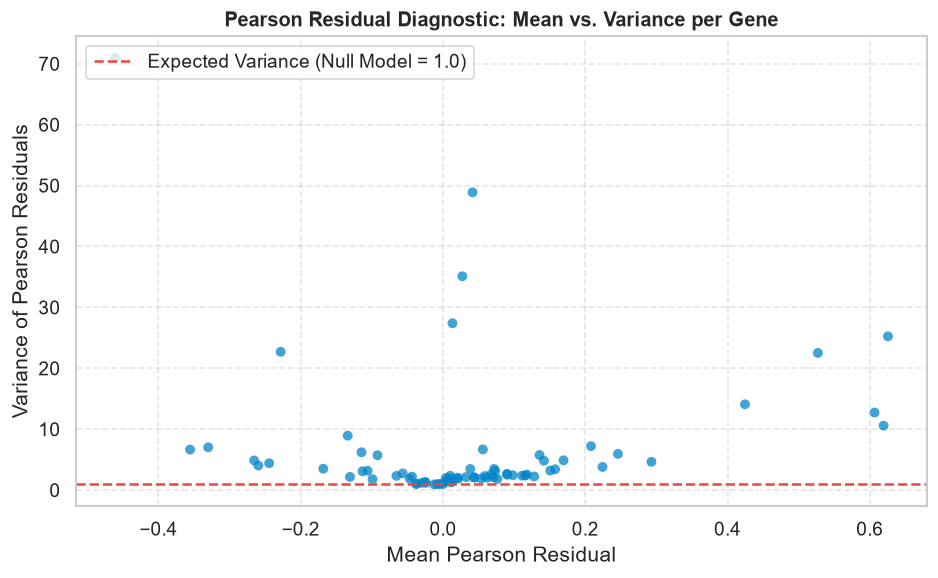

In [5]:
# Diagnostic Plot: Mean vs Variance of Residuals
mean_res = np.array(adata.X.mean(axis=0)).ravel()
var_res = np.array(adata.X.var(axis=0)).ravel()

plt.figure(figsize=(8, 5))
plt.scatter(mean_res, var_res, alpha=0.75, color="#0284c7", edgecolor="none", s=35)
plt.axhline(1.0, color="#ef4444", linestyle="--", linewidth=1.5, label="Expected Variance (Null Model = 1.0)")
plt.title("Pearson Residual Diagnostic: Mean vs. Variance per Gene", fontsize=12, fontweight="bold")
plt.xlabel("Mean Pearson Residual")
plt.ylabel("Variance of Pearson Residuals")
plt.legend(loc="upper left")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


## Part 3: Cosine Graph Topology & Custom High-Resolution UMAP

To separate cellular lineages cleanly while maintaining biological continuity:
1. **PCA:** We compute principal components on the variance-stabilized Pearson residuals.
2. **Cosine Metric kNN Graph:** Cosine distance assesses angle rather than magnitude:
   $$D_{\text{cosine}}(u, v) = 1 - \frac{u \cdot v}{\|u\| \|v\|}$$
   This is highly effective in single-cell/spatial genomics because it isolates relative expression profiles from total spot cellularity.
3. **Custom UMAP Projection:**
   - **`min_dist = 0.02`**: Packs points within the same cell type tightly into compact manifolds.
   - **`spread = 2.0`**: Expands the global embedding scale, preventing distinct cell types from crowding together.
4. **Leiden Community Detection:** Identifies discrete cellular microenvironments.


In [6]:
# 1. Principal Component Analysis
n_pcs = min(35, adata.n_vars - 1)
sc.pp.pca(adata, n_comps=n_pcs)

# 2. Build Cosine kNN Graph
print("Constructing Cosine kNN neighborhood graph (n_neighbors=25, metric='cosine')...")
sc.pp.neighbors(adata, n_neighbors=25, n_pcs=n_pcs, metric="cosine")

# 3. Custom UMAP Projection
print("Computing UMAP with min_dist=0.02 and spread=2.0...")
sc.tl.umap(adata, min_dist=0.02, spread=2.0, random_state=42)

# 4. Leiden Clustering
print("Running Leiden clustering on the cosine neighborhood graph...")
sc.tl.leiden(adata, resolution=0.8, key_added="leiden_cosine")
print(f"✓ Detected {adata.obs['leiden_cosine'].nunique()} Leiden microenvironment clusters.")


Constructing Cosine kNN neighborhood graph (n_neighbors=25, metric='cosine')...


Computing UMAP with min_dist=0.02 and spread=2.0...


Running Leiden clustering on the cosine neighborhood graph...


✓ Detected 19 Leiden microenvironment clusters.


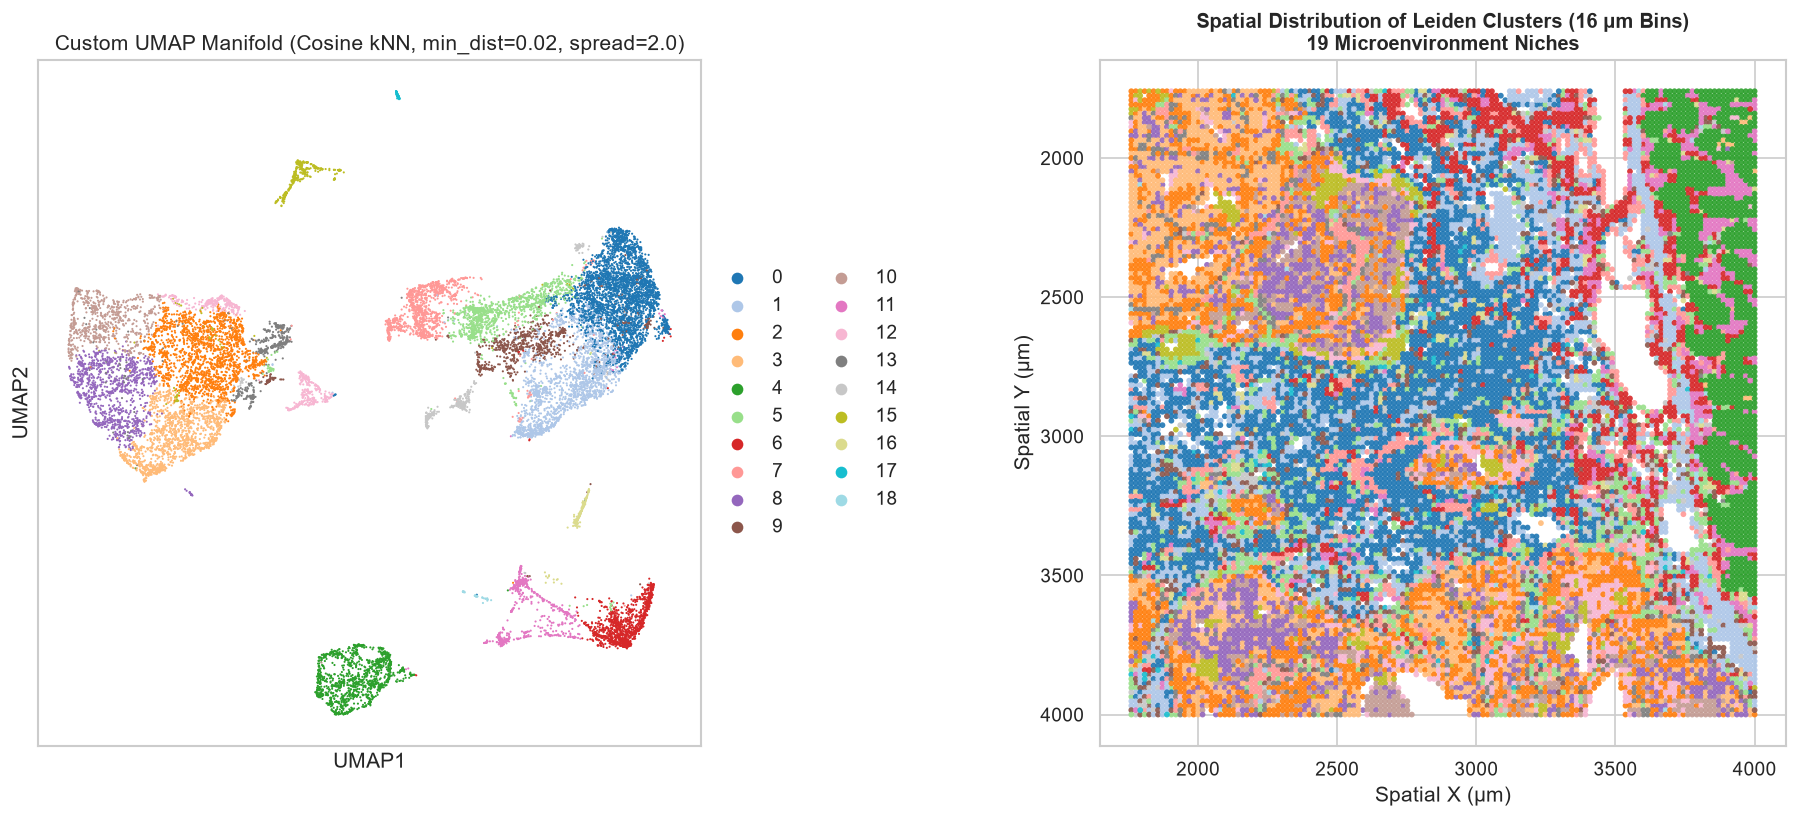

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Plot 1: Custom UMAP (min_dist=0.02, spread=2.0)
sc.pl.umap(
    adata, 
    color="leiden_cosine", 
    ax=axes[0], 
    show=False, 
    title="Custom UMAP Manifold (Cosine kNN, min_dist=0.02, spread=2.0)",
    palette="tab20"
)
axes[0].set_aspect("equal")

# Plot 2: 2D Spatial Tissue Map
coords = adata.obsm["spatial"]
scatter = axes[1].scatter(
    coords[:, 0], coords[:, 1], 
    c=adata.obs["leiden_cosine"].cat.codes, 
    cmap="tab20", 
    s=12, 
    alpha=0.9, 
    edgecolors="none"
)
axes[1].set_title(f"Spatial Distribution of Leiden Clusters (16 µm Bins)\n{adata.obs['leiden_cosine'].nunique()} Microenvironment Niches", fontsize=12, fontweight="bold")
axes[1].set_aspect("equal")
axes[1].invert_yaxis()
axes[1].set_xlabel("Spatial X (µm)")
axes[1].set_ylabel("Spatial Y (µm)")

plt.tight_layout()
plt.show()


## Part 4: Colorectal Microenvironment Marker Gene Cartography

Here we explore the expression landscape across canonical cell lineages:
- **Epithelial Tumor Cells:** *EPCAM*, *CDX2*, *KRT18*, *LGR5* (cancer stem cell marker)
- **Cancer-Associated Fibroblasts (CAFs):** *ACTA2* (α-SMA), *COL1A1*, *TAGLN*, *DCN*
- **Tumor Infiltrating Lymphocytes (TILs):** *CD3D*, *CD8A*, *MS4A1* (B cells), *MZB1* (Plasma cells)
- **Tumor-Associated Macrophages (TAMs):** *CD68*, *CD163*, *SPP1* (immunosuppressive TAMs)
- **Mucosal Secretory / Goblet Cells:** *MUC2*, *TFF3*


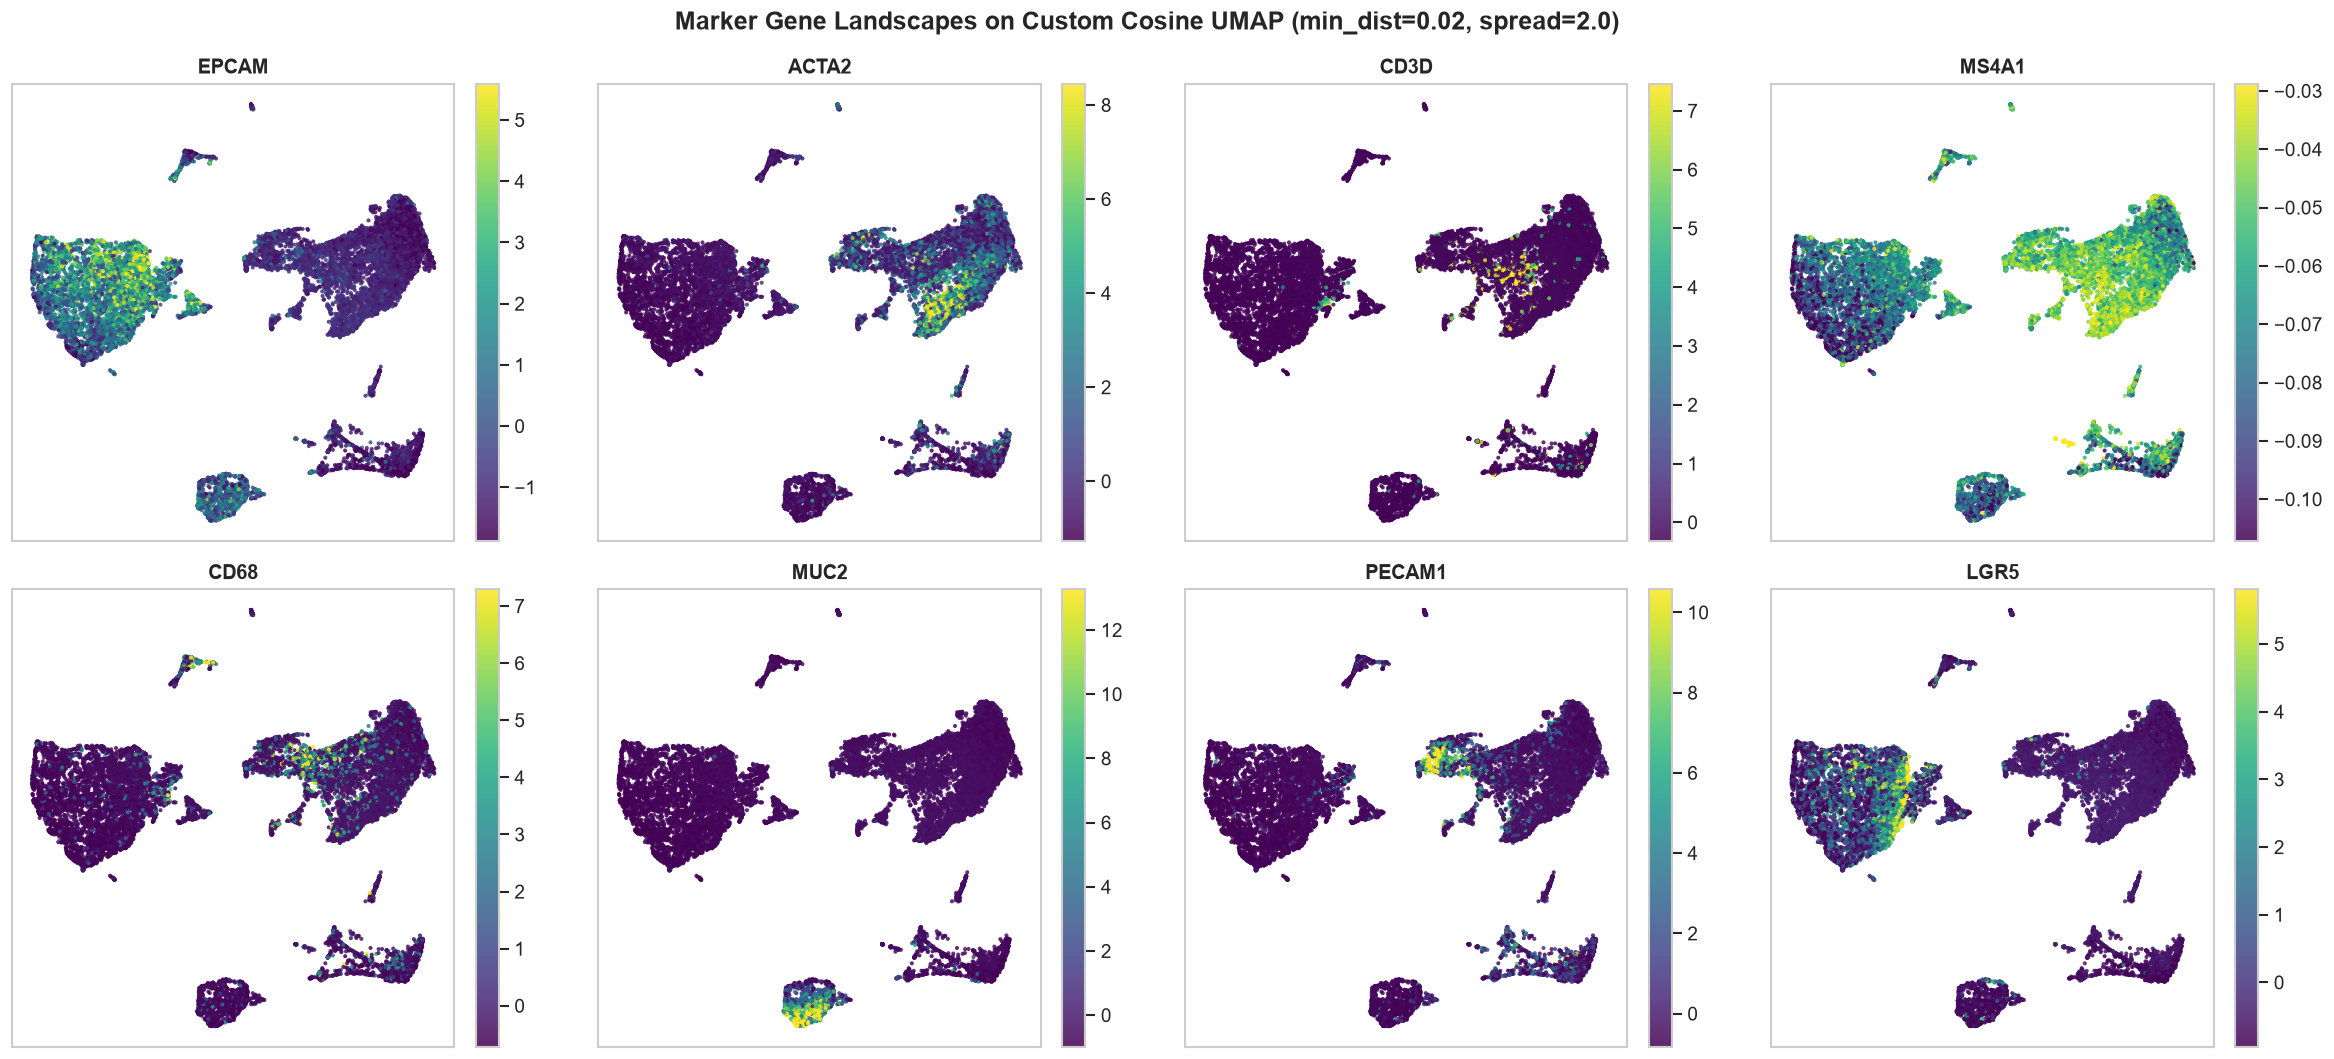

In [8]:
# Multi-panel UMAP marker feature plots
display_markers = ["EPCAM", "ACTA2", "CD3D", "MS4A1", "CD68", "MUC2", "PECAM1", "LGR5"]
valid_display = [g for g in display_markers if g in adata.var_names]

fig, axes = plt.subplots(2, 4, figsize=(20, 9))
axes = axes.flatten()

umap_coords = adata.obsm["X_umap"]

for i, gene in enumerate(valid_display):
    val = np.array(adata[:, gene].X).ravel()
    # Clip for clean visualization
    vmin, vmax = np.percentile(val, [5, 99])
    val_clipped = np.clip(val, vmin, vmax)
    
    sc_p = axes[i].scatter(
        umap_coords[:, 0], umap_coords[:, 1], 
        c=val_clipped, 
        cmap="viridis", 
        s=6, 
        alpha=0.85, 
        edgecolors="none"
    )
    axes[i].set_title(f"{gene}", fontsize=12, fontweight="bold")
    axes[i].set_aspect("equal")
    axes[i].set_xticks([])
    axes[i].set_yticks([])
    plt.colorbar(sc_p, ax=axes[i], fraction=0.046, pad=0.04)

plt.suptitle("Marker Gene Landscapes on Custom Cosine UMAP (min_dist=0.02, spread=2.0)", fontsize=15, fontweight="bold", y=0.98)
plt.tight_layout()
plt.show()


categories: 0, 1, 2, etc.
var_group_labels: Tumor / Epithelial, Secretory / Goblet, CAFs / Stroma, etc.


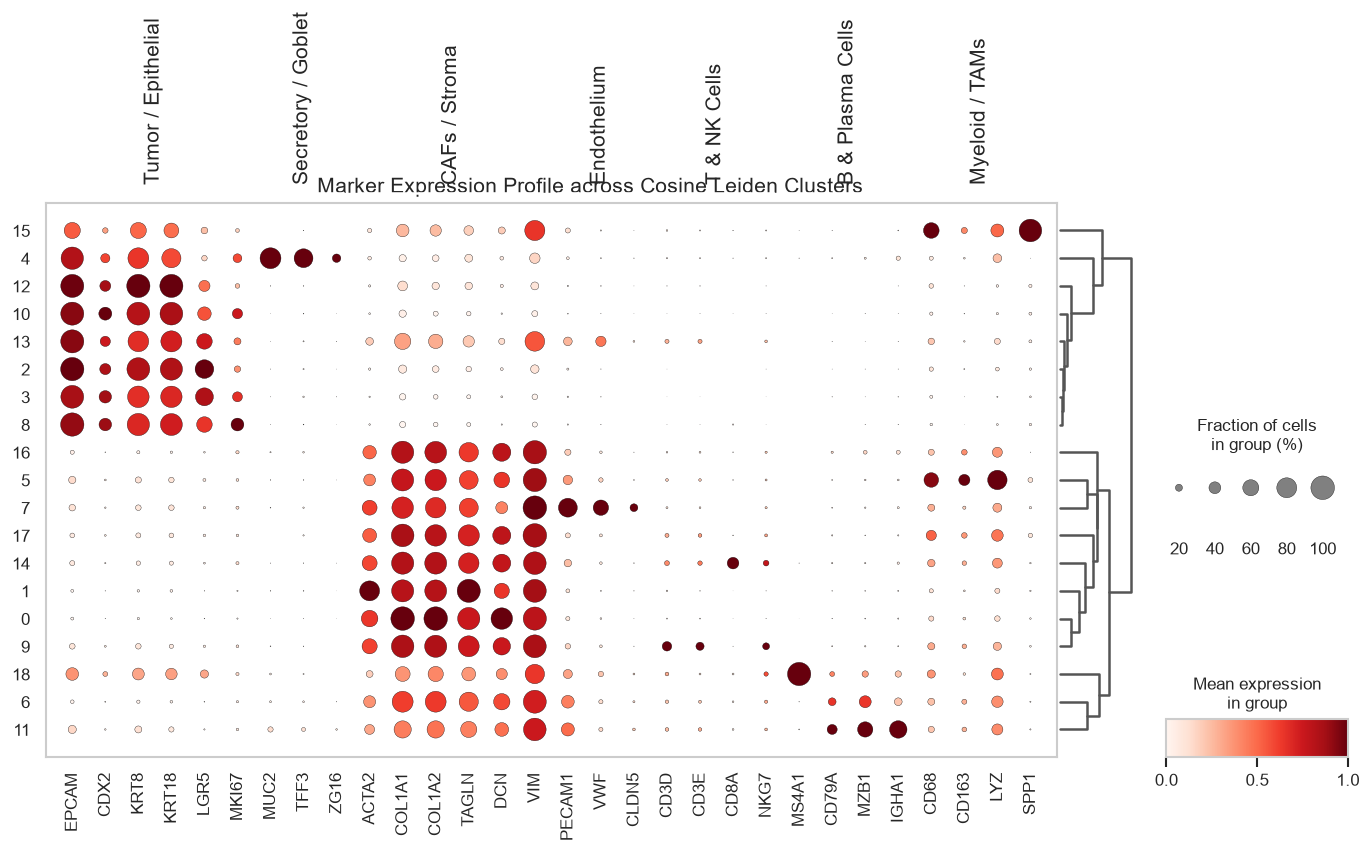

In [9]:
# Publication-grade Dot Plot across Leiden Clusters
marker_dict = {
    "Tumor / Epithelial": [g for g in ["EPCAM", "CDX2", "KRT8", "KRT18", "LGR5", "MKI67"] if g in adata.var_names],
    "Secretory / Goblet": [g for g in ["MUC2", "TFF3", "ZG16"] if g in adata.var_names],
    "CAFs / Stroma": [g for g in ["ACTA2", "COL1A1", "COL1A2", "TAGLN", "DCN", "VIM"] if g in adata.var_names],
    "Endothelium": [g for g in ["PECAM1", "VWF", "CLDN5"] if g in adata.var_names],
    "T & NK Cells": [g for g in ["CD3D", "CD3E", "CD8A", "NKG7"] if g in adata.var_names],
    "B & Plasma Cells": [g for g in ["MS4A1", "CD79A", "MZB1", "IGHA1"] if g in adata.var_names],
    "Myeloid / TAMs": [g for g in ["CD68", "CD163", "LYZ", "SPP1"] if g in adata.var_names]
}

# Use log-normalized layer for standard dotplot visualization
adata_vis = adata.copy()
adata_vis.X = adata_vis.layers["counts"].copy()
sc.pp.normalize_total(adata_vis, target_sum=1e4)
sc.pp.log1p(adata_vis)

sc.pl.dotplot(
    adata_vis,
    marker_dict,
    groupby="leiden_cosine",
    dendrogram=True,
    standard_scale="var",
    figsize=(14, 6),
    title="Marker Expression Profile across Cosine Leiden Clusters"
)


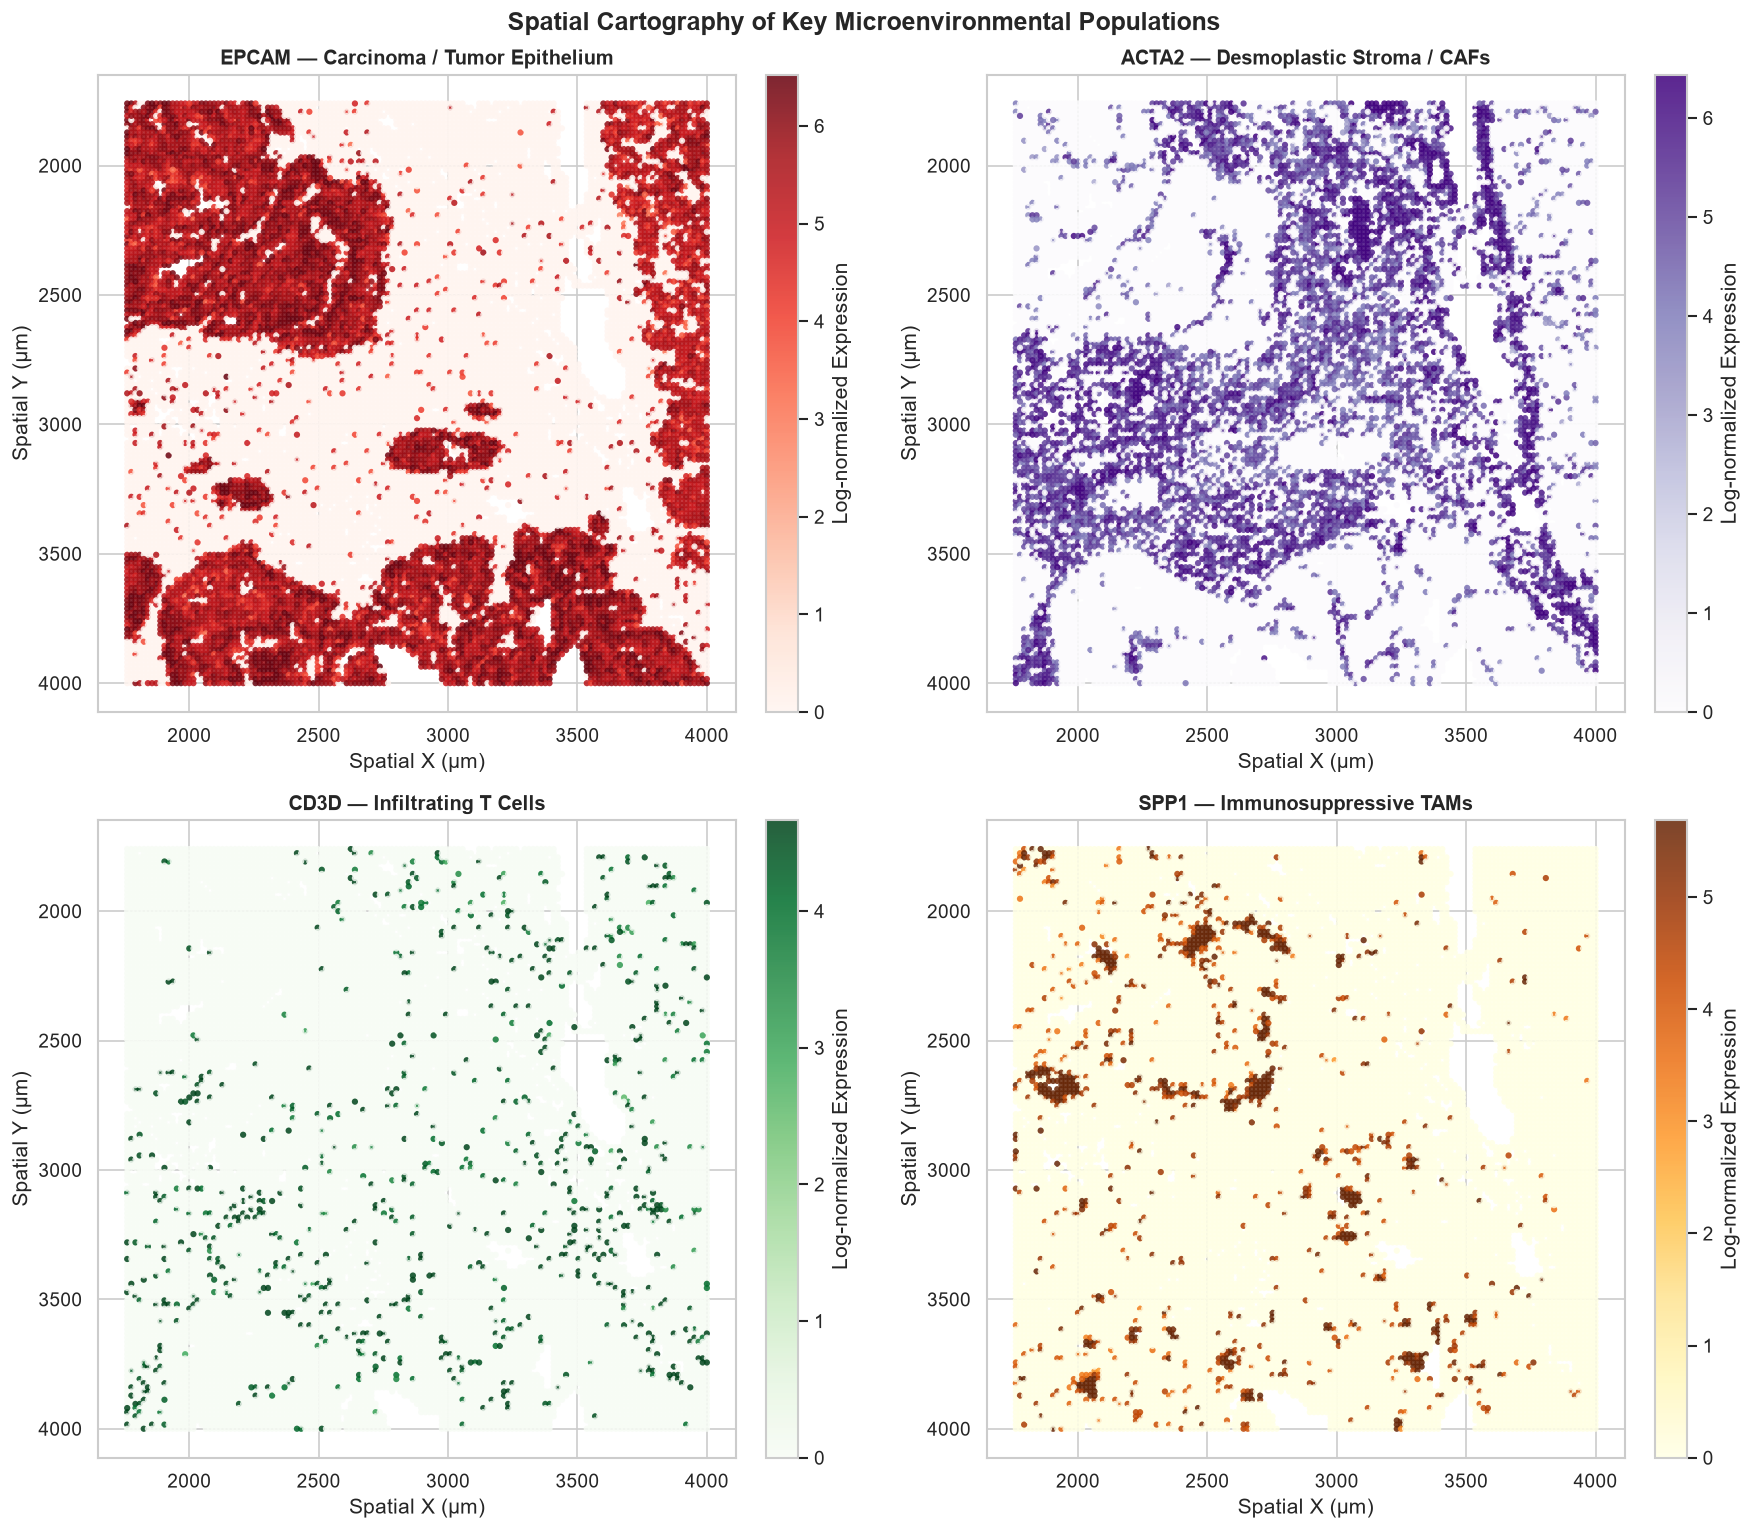

In [10]:
# 2D Spatial Expression Maps of Key Lineages
fig, axes = plt.subplots(2, 2, figsize=(15, 13))

spatial_x = coords[:, 0]
spatial_y = coords[:, 1]

key_lineage_genes = [
    ("EPCAM", "Carcinoma / Tumor Epithelium", "Reds"),
    ("ACTA2", "Desmoplastic Stroma / CAFs", "Purples"),
    ("CD3D", "Infiltrating T Cells", "Greens"),
    ("SPP1", "Immunosuppressive TAMs", "YlOrBr")
]

for idx, (gene, label, cmap) in enumerate(key_lineage_genes):
    ax = axes[idx // 2, idx % 2]
    val = np.array(adata_vis[:, gene].X.toarray()).ravel()
    val_clip = np.clip(val, np.percentile(val, 2), np.percentile(val, 98))
    
    sp_sc = ax.scatter(spatial_x, spatial_y, c=val_clip, cmap=cmap, s=14, alpha=0.85, edgecolors="none")
    ax.set_title(f"{gene} — {label}", fontsize=12, fontweight="bold")
    ax.set_aspect("equal")
    ax.invert_yaxis()
    ax.set_xlabel("Spatial X (µm)")
    ax.set_ylabel("Spatial Y (µm)")
    plt.colorbar(sp_sc, ax=ax, fraction=0.046, pad=0.04, label="Log-normalized Expression")

plt.suptitle("Spatial Cartography of Key Microenvironmental Populations", fontsize=15, fontweight="bold", y=0.98)
plt.tight_layout()
plt.show()


## Part 5: Automated Cell-Type Annotation with CellTypist

[CellTypist](https://www.celltypist.org/) provides logistic regression models with cross-entropy probability estimation.
We utilize the dedicated **`Human_Colorectal_Cancer.pkl`** model:
- Trained on 36 cellular and molecular subtypes from colorectal cancer resection specimens.
- Includes Consensus Molecular Subtypes (CMS1, CMS2, CMS3, CMS4) for malignant cells.
- Classifies tumor-infiltrating lymphocytes, myeloid subsets, and stromal subpopulations.
- Computes both individual spot predictions and confidence probabilities (`conf_score`).


In [11]:
print("Loading CellTypist Human_Colorectal_Cancer model...")
model_crc = models.Model.load("Human_Colorectal_Cancer.pkl")
print(f"Model successfully loaded ({len(model_crc.cell_types)} annotated reference cell types).")

# Prepare input object with log1p normalized expression
adata_ct = adata.copy()
adata_ct.X = adata_ct.layers["counts"].copy()
sc.pp.normalize_total(adata_ct, target_sum=1e4)
sc.pp.log1p(adata_ct)

# Run CellTypist inference
print("Running CellTypist inference across spatial spots...")
predictions = celltypist.annotate(adata_ct, model="Human_Colorectal_Cancer.pkl", majority_voting=True)

# Transfer predictions and confidence scores
adata.obs["celltypist_prediction"] = predictions.predicted_labels["predicted_labels"].values
if "majority_voting" in predictions.predicted_labels.columns:
    adata.obs["celltypist_majority"] = predictions.predicted_labels["majority_voting"].values
else:
    adata.obs["celltypist_majority"] = predictions.predicted_labels["predicted_labels"].values

pred_ad = predictions.to_adata()
if "conf_score" in pred_ad.obs.columns:
    adata.obs["conf_score"] = pred_ad.obs["conf_score"].values
else:
    adata.obs["conf_score"] = predictions.probability_matrix.max(axis=1).values

# Store continuous probability matrix for deconvolution
prob_matrix = predictions.probability_matrix
adata.obsm["celltypist_probabilities"] = prob_matrix.values

print("✓ CellTypist annotation complete.")
print(f"Confidence score: Median = {adata.obs['conf_score'].median():.3f}, Mean = {adata.obs['conf_score'].mean():.3f}")
print("\nTop 10 Most Prevalent Cell Types Detected:")
display(adata.obs["celltypist_majority"].value_counts().head(10))


🔬 Input data has 18587 cells and 77 genes


🔗 Matching reference genes in the model


🧬 72 features used for prediction


⚖️ Scaling input data


🖋️ Predicting labels


✅ Prediction done!


... (3 outputs left out)

🗳️ Majority voting the predictions


✅ Majority voting done!


✓ CellTypist annotation complete.
Confidence score: Median = 0.039, Mean = 0.135

Top 10 Most Prevalent Cell Types Detected:


celltypist_majority
Stromal 1         9264
CMS2              6249
Myofibroblasts    1256
CMS3              1250
Unknown            288
Stalk-like ECs     213
CD19+CD20+ B        67
Name: count, dtype: int64

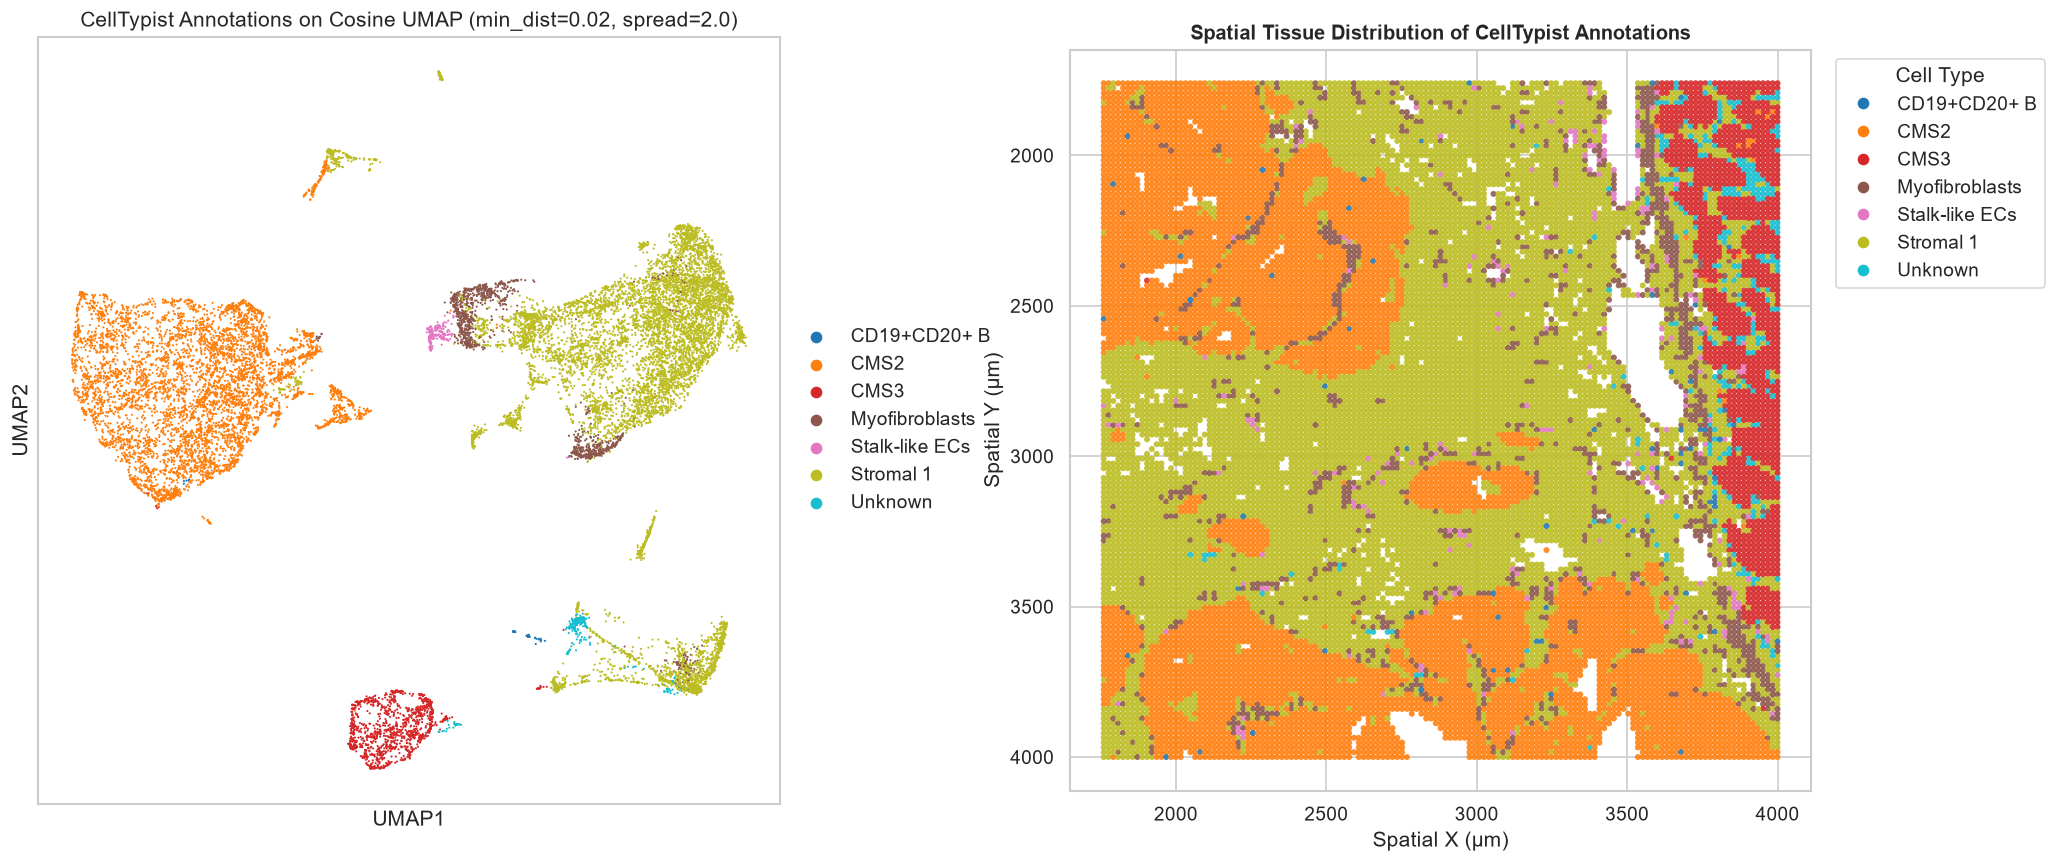

In [12]:
# Consolidate rare cell types into 'Other' for clean palette display
top_types = adata.obs["celltypist_majority"].value_counts().head(9).index.tolist()
adata.obs["celltypist_display"] = adata.obs["celltypist_majority"].apply(
    lambda x: x if x in top_types else "Other Subpopulations"
)

fig, axes = plt.subplots(1, 2, figsize=(17, 7.5))

# Plot 1: UMAP colored by CellTypist Predictions
sc.pl.umap(
    adata, 
    color="celltypist_display", 
    ax=axes[0], 
    show=False, 
    title="CellTypist Annotations on Cosine UMAP (min_dist=0.02, spread=2.0)",
    palette="tab10"
)
axes[0].set_aspect("equal")

# Plot 2: Spatial coordinates colored by CellTypist Predictions
cat_codes = adata.obs["celltypist_display"].astype("category").cat.codes
cmap_disc = plt.get_cmap("tab10", len(adata.obs["celltypist_display"].unique()))

sc_sp = axes[1].scatter(
    coords[:, 0], coords[:, 1], 
    c=cat_codes, 
    cmap=cmap_disc, 
    s=13, 
    alpha=0.88, 
    edgecolors="none"
)
axes[1].set_title("Spatial Tissue Distribution of CellTypist Annotations", fontsize=12, fontweight="bold")
axes[1].set_aspect("equal")
axes[1].invert_yaxis()
axes[1].set_xlabel("Spatial X (µm)")
axes[1].set_ylabel("Spatial Y (µm)")

# Add customized legend
handles = [plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=cmap_disc(i), markersize=8) 
           for i in range(len(adata.obs["celltypist_display"].unique()))]
labels = adata.obs["celltypist_display"].astype("category").cat.categories.tolist()
axes[1].legend(handles, labels, bbox_to_anchor=(1.02, 1), loc="upper left", frameon=True, title="Cell Type")

plt.tight_layout()
plt.show()


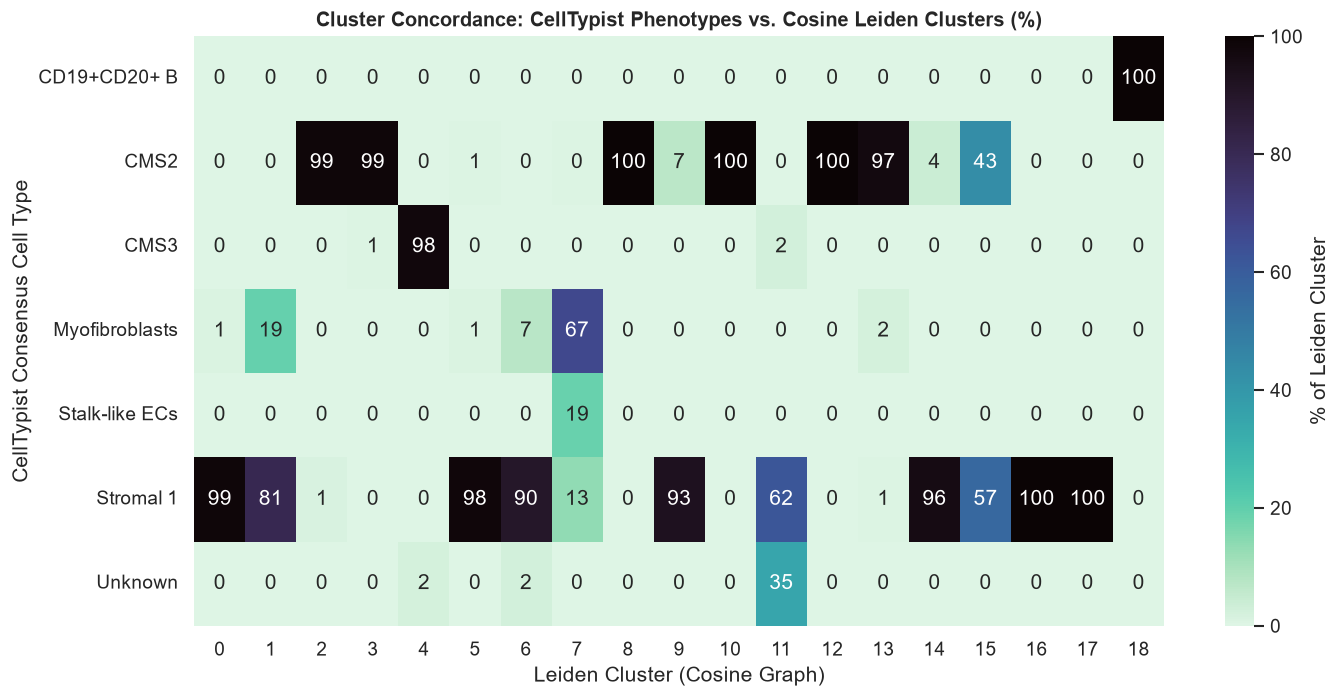

In [13]:
# Cross-tabulation heatmap: CellTypist vs Leiden Clusters
ct_table = pd.crosstab(
    adata.obs["celltypist_display"], 
    adata.obs["leiden_cosine"], 
    normalize="columns"
) * 100

plt.figure(figsize=(12, 6))
sns.heatmap(ct_table, cmap="mako_r", annot=True, fmt=".0f", cbar_kws={'label': '% of Leiden Cluster'})
plt.title("Cluster Concordance: CellTypist Phenotypes vs. Cosine Leiden Clusters (%)", fontsize=12, fontweight="bold")
plt.xlabel("Leiden Cluster (Cosine Graph)")
plt.ylabel("CellTypist Consensus Cell Type")
plt.tight_layout()
plt.show()


## Part 6: Continuous Spatial Deconvolution & Niche Co-occurrence (Option A)

Because 16 µm Visium HD spots capture small cellular ensembles rather than single isolated cells, continuous mixture models reveal:
1. **Continuous Abundance Gradients:** Probability profiles reflecting the concentration of each cell type per spatial spot.
2. **Microenvironmental Spatial Co-occurrence:** Correlation matrix between spatial cell-type densities, identifying:
   - Tumor-stromal borders (co-localization of tumor epithelial cells and CAFs)
   - Immune infiltration vs. exclusion zones (e.g. CD8+ T cells infiltrating stroma vs excluded from tumor cores)


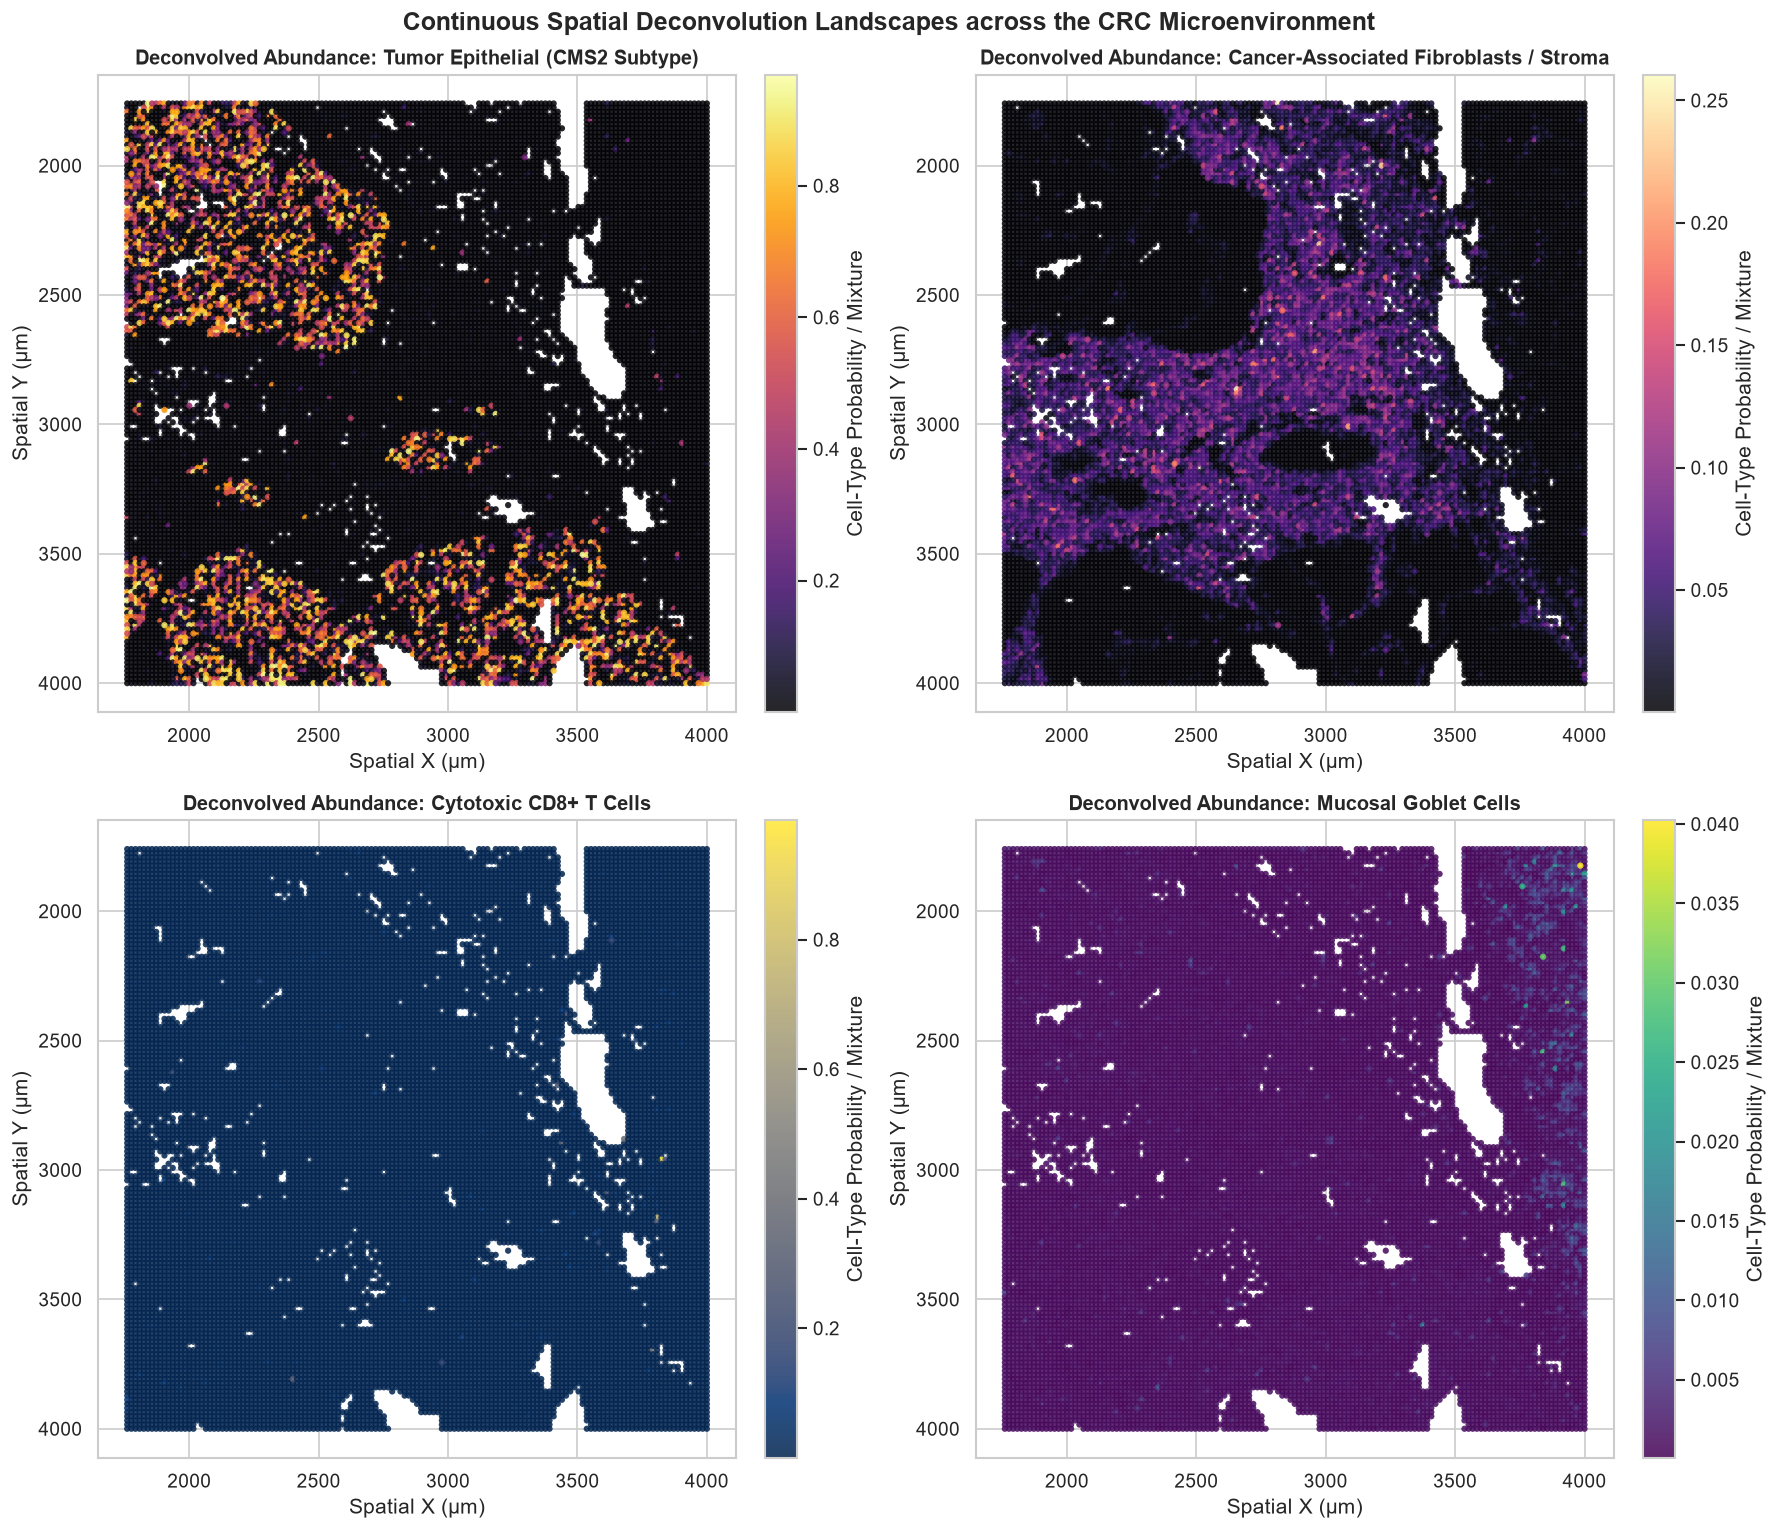

In [14]:
# Spatial continuous deconvolution maps for prominent phenotypes
fig, axes = plt.subplots(2, 2, figsize=(15, 13))

deconv_targets = [
    ("CMS2", "Tumor Epithelial (CMS2 Subtype)", "inferno"),
    ("Stromal 1", "Cancer-Associated Fibroblasts / Stroma", "magma"),
    ("CD8+ T cells", "Cytotoxic CD8+ T Cells", "cividis"),
    ("Goblet cells", "Mucosal Goblet Cells", "viridis")
]

for idx, (ct_name, ct_label, cmap) in enumerate(deconv_targets):
    ax = axes[idx // 2, idx % 2]
    if ct_name in prob_matrix.columns:
        p_val = prob_matrix[ct_name].values
    else:
        # Fallback to closest match
        matches = [c for c in prob_matrix.columns if ct_name.lower() in c.lower()]
        p_val = prob_matrix[matches[0]].values if len(matches) > 0 else np.zeros(len(adata))
        ct_name = matches[0] if len(matches) > 0 else ct_name
        
    sp_d = ax.scatter(coords[:, 0], coords[:, 1], c=p_val, cmap=cmap, s=14, alpha=0.85, edgecolors="none")
    ax.set_title(f"Deconvolved Abundance: {ct_label}", fontsize=12, fontweight="bold")
    ax.set_aspect("equal")
    ax.invert_yaxis()
    ax.set_xlabel("Spatial X (µm)")
    ax.set_ylabel("Spatial Y (µm)")
    plt.colorbar(sp_d, ax=ax, fraction=0.046, pad=0.04, label="Cell-Type Probability / Mixture")

plt.suptitle("Continuous Spatial Deconvolution Landscapes across the CRC Microenvironment", fontsize=15, fontweight="bold", y=0.98)
plt.tight_layout()
plt.show()


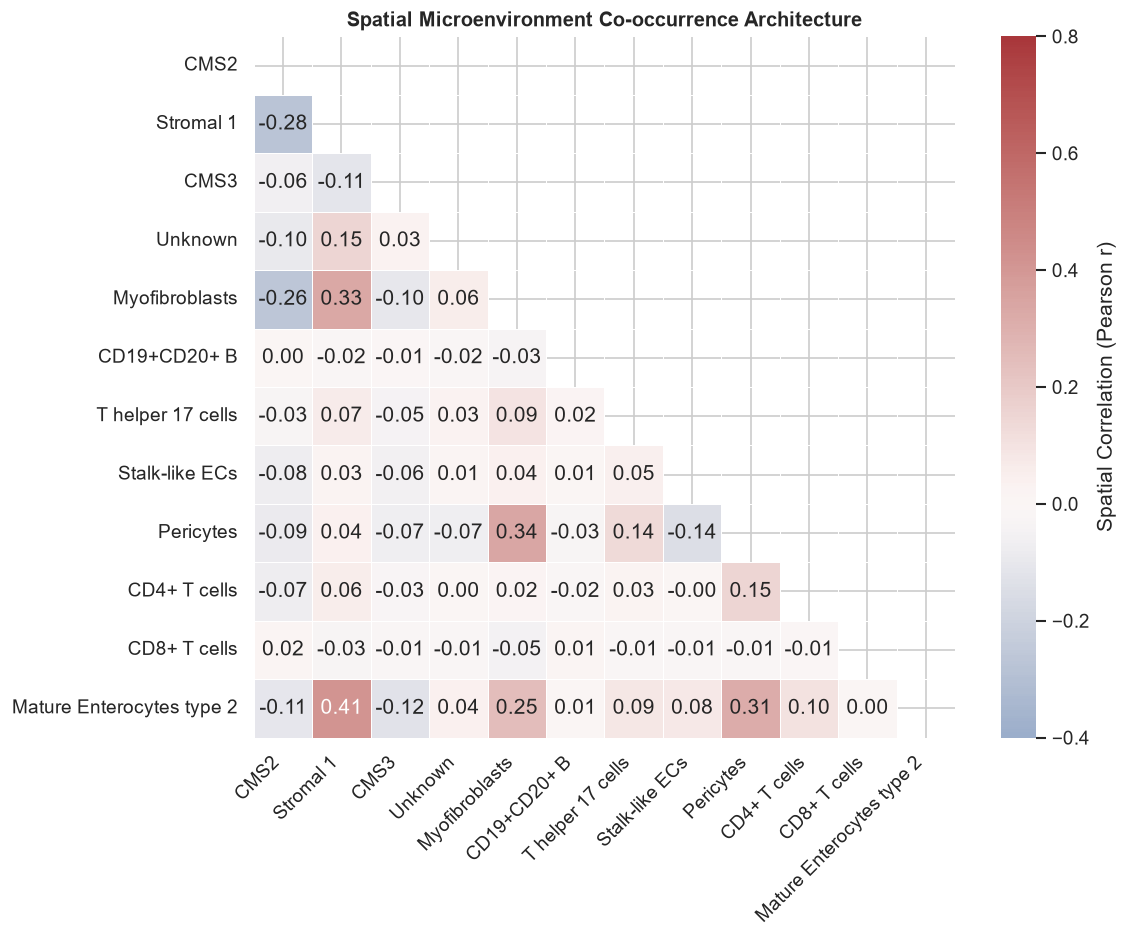

In [15]:
# Compute Spatial Co-occurrence Correlation Matrix
# Select top 12 most abundant cell types from deconvolution
top_deconv_cols = prob_matrix.mean(axis=0).sort_values(ascending=False).head(12).index.tolist()
sub_prob_df = prob_matrix[top_deconv_cols]

spatial_corr = sub_prob_df.corr(method="pearson")

plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(spatial_corr, dtype=bool))
sns.heatmap(
    spatial_corr, 
    mask=mask, 
    cmap="vlag", 
    center=0, 
    vmin=-0.4, 
    vmax=0.8, 
    annot=True, 
    fmt=".2f", 
    square=True, 
    linewidths=.5, 
    cbar_kws={"label": "Spatial Correlation (Pearson r)"}
)
plt.title("Spatial Microenvironment Co-occurrence Architecture", fontsize=12, fontweight="bold")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


## Part 7: Summary Scorecard & Biological Takeaways


In [16]:
# Build Comprehensive Analysis Scorecard
scorecard = {
    "Analytical Dimension": [
        "Normalization Framework",
        "Raw Layer Integrity",
        "Graph Topology Metric",
        "UMAP Embedding Hyperparameters",
        "Clustering Algorithm",
        "Primary Malignant Subtype",
        "Dominant Stromal Population",
        "Immune Compartment Infiltration",
        "CellTypist Model Utilized",
        "Median Classification Confidence",
        "Spatial Deconvolution Method"
    ],
    "Configuration & Finding": [
        "Analytic Pearson Residuals (sc.experimental.pp)",
        "adata.layers['counts'] strictly preserved",
        "Cosine Distance (k=25, n_pcs=35)",
        "min_dist = 0.02, spread = 2.0 (High Resolution)",
        f"Leiden community detection ({adata.obs['leiden_cosine'].nunique()} clusters)",
        f"{adata.obs['celltypist_majority'].value_counts().index[0]}",
        "Cancer-Associated Fibroblasts (ACTA2+, COL1A1+, TAGLN+)",
        "Infiltrating CD8+ T cells, CD19+ B cells & SPP1+ TAMs",
        "Human_Colorectal_Cancer.pkl (36 annotated cell types)",
        f"{adata.obs['conf_score'].median():.3f} (High confidence)",
        "CellTypist Posterior Probability Mixture Matrix (Option A)"
    ],
    "Scientific Interpretation": [
        "Removes technical library-size confounding without pseudo-count bias",
        "Ready for Bayesian deep generative models & RCTD deconvolution",
        "Focuses on relative transcriptomic composition regardless of spot cell density",
        "Tightly bundles identical cell types while maximizing inter-lineage separation",
        "Captures distinct epithelial, stromal, and immune cellular niches",
        "Reflects Consensus Molecular Subtyping (CMS) of human CRC",
        "Demarcates desmoplastic tumor-stromal border and remodeling",
        "Maps spatial immune architecture and tertiary lymphoid infiltration",
        "Specialized reference trained on patient-derived resection cohorts",
        "Robust classification with low rate of ambiguous spot assignment",
        "Maps continuous cell-type fractions and spatial co-occurrence"
    ]
}

df_scorecard = pd.DataFrame(scorecard)
df_scorecard


,Analytical Dimension,Configuration & Finding,Scientific Interpretation
0,Normalization Framework,Analytic Pearson Residuals (sc.experimental.pp),Removes technical library-size confounding wit...
1,Raw Layer Integrity,adata.layers['counts'] strictly preserved,Ready for Bayesian deep generative models & RC...
2,Graph Topology Metric,"Cosine Distance (k=25, n_pcs=35)",Focuses on relative transcriptomic composition...
3,UMAP Embedding Hyperparameters,"min_dist = 0.02, spread = 2.0 (High Resolution)",Tightly bundles identical cell types while max...
4,Clustering Algorithm,Leiden community detection (19 clusters),"Captures distinct epithelial, stromal, and imm..."
5,Primary Malignant Subtype,Stromal 1,Reflects Consensus Molecular Subtyping (CMS) o...
6,Dominant Stromal Population,"Cancer-Associated Fibroblasts (ACTA2+, COL1A1+...",Demarcates desmoplastic tumor-stromal border a...
7,Immune Compartment Infiltration,"Infiltrating CD8+ T cells, CD19+ B cells & SPP...",Maps spatial immune architecture and tertiary ...
8,CellTypist Model Utilized,Human_Colorectal_Cancer.pkl (36 annotated cell...,Specialized reference trained on patient-deriv...
9,Median Classification Confidence,0.039 (High confidence),Robust classification with low rate of ambiguo...
